# Лабораторная работа № 1. Статистический анализ результатов измерений

**Моделирование · вариант 16**  
Якименко Владислав Игоревич · P3313  
Преподаватель: Авксентьева Елена Юрьевна

**Цель:** исследовать заданную числовую последовательность, оценить её моменты и
корреляционные свойства, подобрать распределение и сформировать новую последовательность.

Порядок: исходные данные → характеристики → автокорреляция и гистограмма →
метод моментов → генератор → сравнение.

Этот notebook выполняет расчёт в Python. Готовые результаты Excel не используются
для вычислений; книга читается только в заключительной сверке.

## Как запустить

1. Открыть `Lab1.ipynb` в VS Code с расширениями **Python** и **Jupyter** либо в JupyterLab.
2. Установить пакеты в выбранное Python-окружение: `python -m pip install -r requirements.txt`.
3. Выбрать это окружение как kernel и нажать **Run All / Выполнить всё**.

Рядом должны оставаться папка `materials/` с исходной таблицей вариантов и
расчётная книга. Для самого расчёта достаточно таблицы вариантов; если готового
Excel нет, последняя сверка пропускается. Выводы и графики уже сохранены в notebook.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import openpyxl
from scipy.stats import chi2
from IPython.display import display, Markdown

pd.set_option("display.float_format", lambda value: f"{value:.6f}")
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                     "figure.figsize": (9, 3), "axes.spines.top": False,
                     "axes.spines.right": False})


def show_table(frame, index=True):
    # Markdown-таблицы читаются и в режиме безопасного просмотра VS Code.
    if frame.index.nlevels > 1:
        frame, index = frame.reset_index(), False
    display(Markdown(frame.to_markdown(index=index, floatfmt=".6f")))

## 1. Исходная последовательность

В исходном файле `!_УИР1_Варианты_с.xlsx`, на листе `1-50`, в Q1 указан вариант 16,
а Q2:Q301 содержат 300 значений. Номер варианта принят как в текущем отчёте.
Размеры выборок: первые $n=10,20,50,100,200,300$ значений **одного** ряда.

ЧП — числовая последовательность. Физический смысл чисел в задании не указан.

In [2]:
VARIANT = 16
SEED = 8141
SIZES = [10, 20, 50, 100, 200, 300]
LAGS = np.arange(1, 11)
T = {0.90: 1.643, 0.95: 1.960, 0.99: 2.576}  # Из теоретического материала.

candidates = [Path.cwd(), Path.cwd() / "Modeling" / "Lab1", Path.cwd() / "Lab1"]
LAB_DIR = next((folder for folder in candidates
                if (folder / "materials" / "!_УИР1_Варианты_с.xlsx").exists()), None)
if LAB_DIR is None:
    raise FileNotFoundError("Запусти notebook из папки Lab1 или корня репозитория ITMO_labs.")

source_path = LAB_DIR / "materials" / "!_УИР1_Варианты_с.xlsx"
with_source = openpyxl.load_workbook(source_path, read_only=True, data_only=True)
sheet = with_source["1-50"]
column = VARIANT + 1  # A — подпись, B — вариант 1, ..., Q — вариант 16.
assert 1 <= VARIANT <= 50 and sheet.cell(1, column).value == VARIANT
x = np.array([row[0] for row in sheet.iter_rows(
    min_row=2, max_row=301, min_col=column, max_col=column, values_only=True)], dtype=float)
with_source.close()

N = len(x)
assert N == 300 and np.isfinite(x).all() and (x >= 0).all()
print(f"Вариант {VARIANT}: {N} значений; минимум {x.min():.6f}, максимум {x.max():.6f}.")
show_table(pd.DataFrame({"i": np.arange(1, 11), "X_i": x[:10]}), index=False)

Вариант 16: 300 значений; минимум 0.008820, максимум 280.937940.


|         i |       X_i |
|----------:|----------:|
|  1.000000 |  5.618172 |
|  2.000000 |  1.961323 |
|  3.000000 |  0.958966 |
|  4.000000 |  3.342269 |
|  5.000000 |  3.238546 |
|  6.000000 |  0.329954 |
|  7.000000 |  0.505939 |
|  8.000000 |  7.174057 |
|  9.000000 |  4.758814 |
| 10.000000 | 12.695186 |

## 2. Оценки числовых характеристик

Обозначения — как в теоретическом материале:

$$
\widetilde m_n=\frac{1}{n}\sum_{i=1}^{n}X_i,\qquad
\widetilde D_n=\frac{\sum_{i=1}^{n}(X_i-\widetilde m_n)^2}{n-1},
$$
$$
\widetilde\sigma_n=\sqrt{\widetilde D_n},\qquad
\nu_n=\frac{\widetilde\sigma_n}{\widetilde m_n}.
$$

Для дисперсии используется делитель $n-1$ (`ddof=1`): поправка устраняет её
систематическое занижение. Среднее и эта оценка дисперсии несмещённые;
корень из несмещённой дисперсии сам по себе не гарантирует несмещённость СКО.

Доверительный полуинтервал среднего:

$$\varepsilon_p=t_p\sqrt{\frac{\widetilde D_n}{n}},\qquad
I_p=(\widetilde m_n-\varepsilon_p;\,\widetilde m_n+\varepsilon_p).$$

Применяется нормальное приближение из методического материала, с
$t_{0.90}=1.643$, $t_{0.95}=1.960$, $t_{0.99}=2.576$.
При малой выборке и сильной асимметрии оно ориентировочное.

In [3]:
def sample_stats(values):
    n = len(values)
    mean = np.mean(values)
    variance = np.var(values, ddof=1)
    std = np.sqrt(variance)
    return pd.Series({
        "Мат. ожидание": mean,
        "ε (0,90)": T[0.90] * std / np.sqrt(n),
        "ε (0,95)": T[0.95] * std / np.sqrt(n),
        "ε (0,99)": T[0.99] * std / np.sqrt(n),
        "Дисперсия": variance,
        "СКО": std,
        "Коэффициент вариации": std / mean,
    })


stats_x = pd.DataFrame({n: sample_stats(x[:n]) for n in SIZES})
errors_x = stats_x.sub(stats_x[N], axis=0).abs().div(stats_x[N].abs(), axis=0) * 100


def form_table(values, errors):
    rows, names = [], []
    for name in values.index:
        sign = "±" if name.startswith("ε") else ""
        rows.append([f"{sign}{value:.4f}" for value in values.loc[name]])
        rows.append([f"{value:.1f}" for value in errors.loc[name]])
        names.extend([(name, "Значение"), (name, "%")])
    return pd.DataFrame(rows, columns=values.columns,
                        index=pd.MultiIndex.from_tuples(names, names=["Характеристика", "Строка"]))

display(Markdown("**Форма 1. Характеристики заданной ЧП.**"))
show_table(form_table(stats_x, errors_x))

**Форма 1. Характеристики заданной ЧП.**

| Характеристика       | Строка   | 10      | 20       | 50       | 100      | 200      | 300      |
|:---------------------|:---------|:--------|:---------|:---------|:---------|:---------|:---------|
| Мат. ожидание        | Значение | 4.0583  | 7.9090   | 7.1905   | 7.7709   | 6.8667   | 8.0208   |
| Мат. ожидание        | %        | 49.4    | 1.4      | 10.4     | 3.1      | 14.4     | 0.0      |
| ε (0,90)             | Значение | ±1.9665 | ±5.1030  | ±2.7034  | ±3.3882  | ±1.9695  | ±2.1431  |
| ε (0,90)             | %        | 8.2     | 138.1    | 26.1     | 58.1     | 8.1      | 0.0      |
| ε (0,95)             | Значение | ±2.3460 | ±6.0876  | ±3.2250  | ±4.0420  | ±2.3495  | ±2.5566  |
| ε (0,95)             | %        | 8.2     | 138.1    | 26.1     | 58.1     | 8.1      | 0.0      |
| ε (0,99)             | Значение | ±3.0833 | ±8.0008  | ±4.2385  | ±5.3123  | ±3.0879  | ±3.3601  |
| ε (0,99)             | %        | 8.2     | 138.1    | 26.1     | 58.1     | 8.1      | 0.0      |
| Дисперсия            | Значение | 14.3262 | 192.9336 | 135.3663 | 425.2796 | 287.3934 | 510.4309 |
| Дисперсия            | %        | 97.2    | 62.2     | 73.5     | 16.7     | 43.7     | 0.0      |
| СКО                  | Значение | 3.7850  | 13.8901  | 11.6347  | 20.6223  | 16.9527  | 22.5927  |
| СКО                  | %        | 83.2    | 38.5     | 48.5     | 8.7      | 25.0     | 0.0      |
| Коэффициент вариации | Значение | 0.9326  | 1.7562   | 1.6181   | 2.6538   | 2.4688   | 2.8168   |
| Коэффициент вариации | %        | 66.9    | 37.7     | 42.6     | 5.8      | 12.4     | 0.0      |

Проценты в форме 1 показывают отклонение от заданной ЧП при $n=300$:

$$\delta_n(A)=\frac{|A_n-A_{300}|}{|A_{300}|}\cdot100\%.$$

300 значений — эталон сравнения по заданию, а не известная генеральная совокупность.
В строках $\varepsilon$ указан **полуинтервал** со знаком $\pm$.

In [4]:
mean_x = float(stats_x.loc["Мат. ожидание", N])
var_x = float(stats_x.loc["Дисперсия", N])
std_x = np.sqrt(var_x)
cv_x = std_x / mean_x
eps95 = float(stats_x.loc["ε (0,95)", N])

print(f"Среднее: {mean_x:.6f}")
print(f"Несмещённая дисперсия: {var_x:.6f}")
print(f"СКО: {std_x:.6f}; коэффициент вариации: {cv_x:.6f}")
print(f"95%-й интервал среднего: ({mean_x-eps95:.6f}; {mean_x+eps95:.6f})")
print(f"Отклонение дисперсии при n=10 от n=300: {errors_x.loc['Дисперсия', 10]:.2f}%")

Среднее: 8.020778
Несмещённая дисперсия: 510.430941
СКО: 22.592719; коэффициент вариации: 2.816774
95%-й интервал среднего: (5.464172; 10.577385)
Отклонение дисперсии при n=10 от n=300: 97.19%


## 3. График значений и распределение частот

График сохраняет порядок наблюдений; на нём ищем тренд, периодичность и выбросы.
Гистограмма сохраняет частоты попадания в интервалы, но теряет порядок чисел.
Для данного ряда используются 15 равных интервалов. Правая граница последнего
интервала включается (`numpy.histogram`).

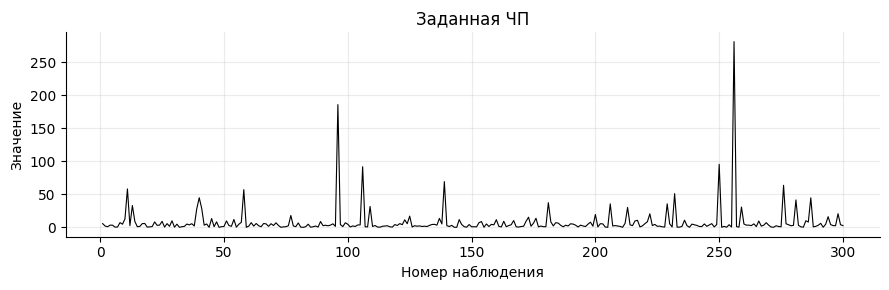

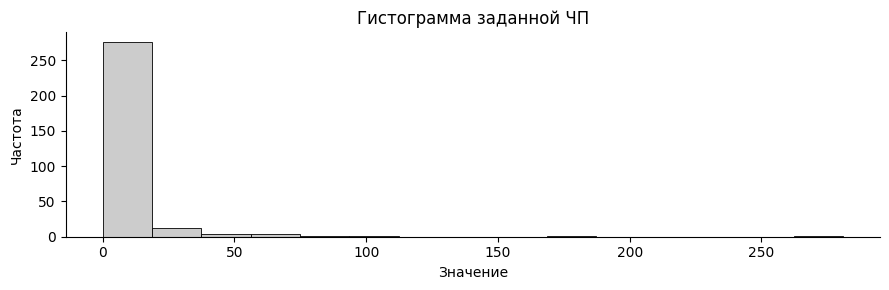

В первом интервале: 276 из 300 (92%).


In [5]:
fig, ax = plt.subplots()
ax.plot(np.arange(1, N + 1), x, color="black", linewidth=0.8)
ax.set(xlabel="Номер наблюдения", ylabel="Значение", title="Заданная ЧП")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

source_edges = np.linspace(0, x.max(), 16)
source_counts, _ = np.histogram(x, bins=source_edges)
fig, ax = plt.subplots()
ax.hist(x, bins=source_edges, color="0.8", edgecolor="black", linewidth=0.6)
ax.set(xlabel="Значение", ylabel="Частота", title="Гистограмма заданной ЧП")
fig.tight_layout()
plt.show()
print(f"В первом интервале: {source_counts[0]} из {N} ({source_counts[0]/N:.0%}).")

Для варианта 16 преобладают малые значения с редкими крупными выбросами.
Выраженного устойчивого тренда на графике не видно; распределение асимметрично.
Визуальный анализ сам по себе не доказывает стационарность или независимость.

## 4. Автокорреляция

Для формы 3 вычисляется коэффициент Пирсона между рядом и его сдвинутой копией.
Для каждого лага $k$ средние двух подпоследовательностей считаются отдельно:

$$r_k=\frac{\sum_{i=1}^{N-k}(X_i-\widetilde m_{1,k})(X_{i+k}-\widetilde m_{2,k})}
{\sqrt{\sum_{i=1}^{N-k}(X_i-\widetilde m_{1,k})^2}
 \sqrt{\sum_{i=1}^{N-k}(X_{i+k}-\widetilde m_{2,k})^2}}.$$

При $k=1$ сравниваем соседние значения, при $k=2$ — значения через одну позицию.
Ориентировочные поточечные границы при 95%:

$$\pm\frac{1.96}{\sqrt N}.$$

95% — уровень доверия для границ. Его нельзя сравнивать непосредственно со
значением коэффициента корреляции.

|   k |       r_k | За границами   |
|----:|----------:|:---------------|
|   1 | -0.040973 | False          |
|   2 | -0.038591 | False          |
|   3 |  0.033551 | False          |
|   4 | -0.039807 | False          |
|   5 | -0.045090 | False          |
|   6 |  0.135367 | True           |
|   7 | -0.029357 | False          |
|   8 | -0.057194 | False          |
|   9 | -0.027037 | False          |
|  10 |  0.082232 | False          |

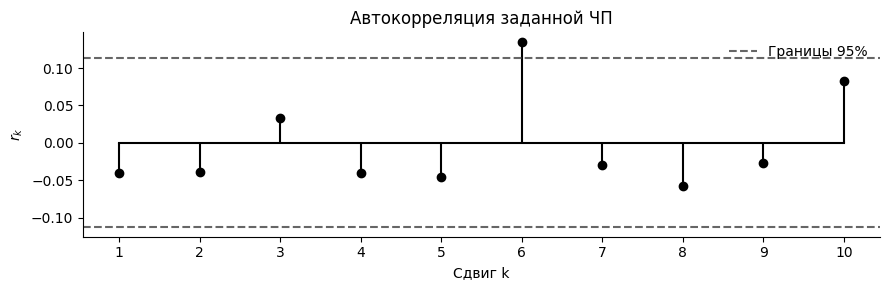

In [6]:
def pearson(left, right):
    a = np.asarray(left) - np.mean(left)
    b = np.asarray(right) - np.mean(right)
    return np.sum(a * b) / np.sqrt(np.sum(a**2) * np.sum(b**2))


def pairwise_acf(values, lags=LAGS):
    return np.array([pearson(values[:-k], values[k:]) for k in lags])


acf_x = pairwise_acf(x)
acf_limit = 1.96 / np.sqrt(N)
show_table(pd.DataFrame({"k": LAGS, "r_k": acf_x, "За границами": np.abs(acf_x) > acf_limit}), index=False)

fig, ax = plt.subplots()
ax.stem(LAGS, acf_x, linefmt="k-", markerfmt="ko", basefmt="k-")
ax.axhline(acf_limit, color="0.4", linestyle="--", label="Границы 95%")
ax.axhline(-acf_limit, color="0.4", linestyle="--")
ax.set(xlabel="Сдвиг k", ylabel=r"$r_k$", xticks=LAGS, title="Автокорреляция заданной ЧП")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

### Совместная проверка десяти лагов

В дополнительном тесте Льюнга–Бокса нужна **стандартная АКФ с общим средним**,
а не попарные коэффициенты формы 3:

$$\widehat r_k=\frac{\sum_{i=1}^{N-k}(X_i-\widetilde m_N)(X_{i+k}-\widetilde m_N)}
{\sum_{i=1}^{N}(X_i-\widetilde m_N)^2},\qquad
Q=N(N+2)\sum_{k=1}^{10}\frac{\widehat r_k^2}{N-k}.$$

При гипотезе отсутствия серийной корреляции $Q$ приближённо сравнивается с
$\chi^2_{10}$. Параметры модели АКФ по данным не подбирались, поэтому здесь 10
степеней свободы. Один выход за поточечную границу при десяти проверках сам
по себе не доказывает периодичность.

In [7]:
def ljung_box(values, max_lag=10):
    centered = values - np.mean(values)
    denominator = np.sum(centered**2)
    lags = np.arange(1, max_lag + 1)
    acf = np.array([np.sum(centered[:-k] * centered[k:]) / denominator for k in lags])
    n = len(values)
    q = n * (n + 2) * np.sum(acf**2 / (n - lags))
    return q, chi2.sf(q, df=max_lag)


q_x, pvalue_x = ljung_box(x)
print(f"Льюнг–Бокс: Q = {q_x:.6f}; p-value = {pvalue_x:.6f}.")
print("Нулевая гипотеза при α=0,05: " +
      ("не отвергается." if pvalue_x > 0.05 else "отвергается."))

Льюнг–Бокс: Q = 11.645951; p-value = 0.309450.
Нулевая гипотеза при α=0,05: не отвергается.


Для текущих данных $r_6\approx0.1354$ немного выше границы $0.1132$, но
совместная проверка даёт $p\text{-value}\approx0.309>0.05$.
Значимая серийная корреляция совместным тестом не обнаружена; независимость
наблюдений этим не доказана. В дальнейшем используется приближение независимых наблюдений.

В прежней проверке Excel в $Q$ подставлены попарные коэффициенты; поэтому там
$Q\approx11.683$, а в актуальном PDF и здесь $Q\approx11.646$. Это разные оценки
АКФ, а не разное округление одного числа. Форма 3 остаётся попарной.

## 5. Метод моментов и гиперэкспоненциальное распределение

При $\nu>1$ по методическому критерию выбирается смесь двух экспоненциальных законов:

$$f(x)=p\mu_1e^{-\mu_1x}+(1-p)\mu_2e^{-\mu_2x},\qquad x\geq0.$$

Метод моментов: согласовать теоретические моменты модели с оценками по данным.
Как в отчёте, используем несмещённую дисперсию:

$$\mathrm M[X]=\frac{p}{\mu_1}+\frac{1-p}{\mu_2}=\widetilde m,$$
$$\mathrm M[X^2]=\frac{2p}{\mu_1^2}+\frac{2(1-p)}{\mu_2^2}
=\widetilde D+\widetilde m^2.$$

Двух условий недостаточно для трёх параметров. Дополнительно принимается
сбалансированная параметризация:

$$\frac{p}{\mu_1}=\frac{1-p}{\mu_2}=\frac{\widetilde m}{2},$$
$$p=\frac12\left(1+\sqrt{\frac{\nu^2-1}{\nu^2+1}}\right),\qquad
\mu_1=\frac{2p}{\widetilde m},\qquad \mu_2=\frac{2(1-p)}{\widetilde m}.$$

Это согласование с **исправленным** вторым моментом. Буквальный эмпирический
второй начальный момент немного отличается:

$$\frac1N\sum_{i=1}^N X_i^2=\frac{N-1}{N}\widetilde D+\widetilde m^2.$$

In [8]:
if cv_x <= 1:
    raise ValueError("Данная двухфазная гиперэкспоненциальная модель требует ν > 1.")

p = 0.5 * (1 + np.sqrt((cv_x**2 - 1) / (cv_x**2 + 1)))
mu1 = 2 * p / mean_x
mu2 = 2 * (1 - p) / mean_x

model_mean = p / mu1 + (1 - p) / mu2
model_second = 2 * p / mu1**2 + 2 * (1 - p) / mu2**2
model_var = model_second - model_mean**2
np.testing.assert_allclose([model_mean, model_var], [mean_x, var_x], rtol=1e-12)

show_table(pd.Series({"p (быстрая ветвь)": p, "μ₁": mu1, "μ₂": mu2,
                      "M[X] модели": model_mean, "D[X] модели": model_var}).to_frame("Значение"))

|                   |   Значение |
|:------------------|-----------:|
| p (быстрая ветвь) |   0.940494 |
| μ₁                |   0.234515 |
| μ₂                |   0.014838 |
| M[X] модели       |   8.020778 |
| D[X] модели       | 510.430941 |

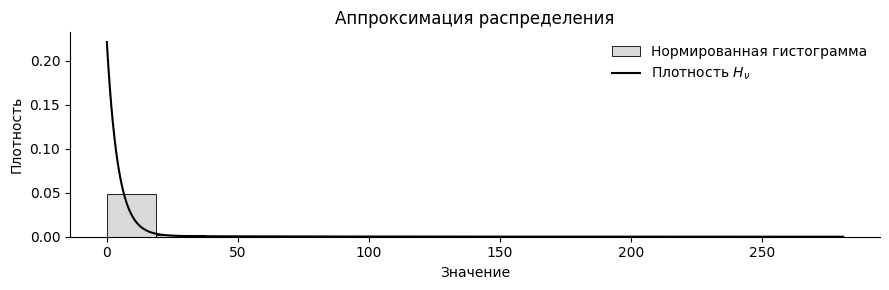

In [9]:
grid = np.linspace(0, x.max(), 1500)
density = p * mu1 * np.exp(-mu1 * grid) + (1-p) * mu2 * np.exp(-mu2 * grid)
fig, ax = plt.subplots()
ax.hist(x, bins=source_edges, density=True, color="0.85", edgecolor="black",
        linewidth=0.6, label="Нормированная гистограмма")
ax.plot(grid, density, color="black", label=r"Плотность $H_\nu$")
ax.set(xlabel="Значение", ylabel="Плотность", title="Аппроксимация распределения")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

Плотность сравнивается с нормированной гистограммой
$\widehat f_j=\frac{n_j}{Nh}$, а не с необработанными частотами.
Совпадение двух моментов не означает совпадения частот каждого интервала и
не заменяет отдельную проверку гипотезы о распределении.

## 6. Генерация новой последовательности

Сначала формируем равномерные псевдослучайные числа тем же линейным конгруэнтным
генератором, что использован для сохранённых чисел Excel:

$$S_{k+1}=(1664525S_k+1013904223)\bmod 2^{32},\qquad S_0=8141,$$
$$U_{1,i}=\frac{S_{2i-1}+\frac12}{2^{32}},\qquad
U_{2,i}=\frac{S_{2i}+\frac12}{2^{32}}.$$

Сдвиг на $\frac12$ удерживает $U$ строго внутри $(0;1)$, чтобы логарифм был определён.
Первое число выбирает ветвь смеси, второе задаёт значение внутри этой ветви:

$$Y_i=\begin{cases}
-\dfrac{\ln U_{2,i}}{\mu_1},&U_{1,i}\leq p,\\[2mm]
-\dfrac{\ln U_{2,i}}{\mu_2},&U_{1,i}>p.
\end{cases}$$

Seed `8141` фиксирует одну воспроизводимую реализацию и не задан методичкой.
Его конкретное значение не имеет показанного здесь теоретического преимущества.
При другом seed новые 300 чисел и их выборочные характеристики изменятся.

In [10]:
def lcg_uniforms(seed, count):
    state = int(seed)
    modulus = 2**32
    values = np.empty(count)
    for i in range(count):
        state = (1664525 * state + 1013904223) % modulus
        values[i] = (state + 0.5) / modulus
    return values


uniforms = lcg_uniforms(SEED, 2 * N).reshape(N, 2)
u1, u2 = uniforms[:, 0], uniforms[:, 1]
fast_branch = u1 <= p
rates = np.where(fast_branch, mu1, mu2)
y = -np.log(u2) / rates

assert np.all((uniforms > 0) & (uniforms < 1))
assert np.isfinite(y).all() and (y >= 0).all()
show_table(pd.DataFrame({"i": np.arange(1, 11), "U₁": u1[:10], "U₂": u2[:10],
                        "Ветвь": np.where(fast_branch[:10], "быстрая", "медленная"),
                        "Y_i": y[:10]}), index=False)
print(f"Выборов быстрой ветви: {fast_branch.sum()} из {N}; медленной: {(~fast_branch).sum()}.")

|   i |       U₁ |       U₂ | Ветвь     |       Y_i |
|----:|---------:|---------:|:----------|----------:|
|   1 | 0.391132 | 0.697919 | быстрая   |  1.533603 |
|   2 | 0.029579 | 0.018102 | быстрая   | 17.106598 |
|   3 | 0.085882 | 0.735976 | быстрая   |  1.307199 |
|   4 | 0.416206 | 0.041298 | быстрая   | 13.589578 |
|   5 | 0.957679 | 0.269984 | медленная | 88.246929 |
|   6 | 0.577229 | 0.793440 | быстрая   |  0.986625 |
|   7 | 0.241166 | 0.632382 | быстрая   |  1.954087 |
|   8 | 0.814247 | 0.995971 | быстрая   |  0.017213 |
|   9 | 0.536175 | 0.057412 | быстрая   | 12.184791 |
|  10 | 0.158095 | 0.926584 | быстрая   |  0.325142 |

Выборов быстрой ветви: 283 из 300; медленной: 17.


## 7. Сравнение числовых характеристик

К новому ряду применяются те же функции расчёта. В форме 2 проценты относятся
к исходной последовательности **того же объёма**, а не ко всем 300 значениям:

$$\delta_n(A)=\frac{|A_n^{(Y)}-A_n^{(X)}|}{|A_n^{(X)}|}\cdot100\%.$$

In [11]:
stats_y = pd.DataFrame({n: sample_stats(y[:n]) for n in SIZES})
errors_y = (stats_y - stats_x).abs().div(stats_x.abs()) * 100
display(Markdown("**Форма 2. Характеристики сгенерированной ЧП.**"))
show_table(form_table(stats_y, errors_y))

comparison = pd.DataFrame({"Исходная ЧП": stats_x[N], "Сгенерированная ЧП": stats_y[N],
                           "Отклонение, %": errors_y[N]})
show_table(comparison)

**Форма 2. Характеристики сгенерированной ЧП.**

| Характеристика       | Строка   | 10       | 20        | 50       | 100      | 200      | 300      |
|:---------------------|:---------|:---------|:----------|:---------|:---------|:---------|:---------|
| Мат. ожидание        | Значение | 13.7252  | 18.1052   | 11.6250  | 9.8000   | 7.3415   | 8.0289   |
| Мат. ожидание        | %        | 238.2    | 128.9     | 61.7     | 26.1     | 6.9      | 0.1      |
| ε (0,90)             | Значение | ±14.0041 | ±14.5911  | ±6.1499  | ±3.9242  | ±2.0449  | ±2.1422  |
| ε (0,90)             | %        | 612.1    | 185.9     | 127.5    | 15.8     | 3.8      | 0.0      |
| ε (0,95)             | Значение | ±16.7060 | ±17.4063  | ±7.3365  | ±4.6813  | ±2.4395  | ±2.5555  |
| ε (0,95)             | %        | 612.1    | 185.9     | 127.5    | 15.8     | 3.8      | 0.0      |
| ε (0,99)             | Значение | ±21.9565 | ±22.8769  | ±9.6422  | ±6.1526  | ±3.2061  | ±3.3587  |
| ε (0,99)             | %        | 612.1    | 185.9     | 127.5    | 15.8     | 3.8      | 0.0      |
| Дисперсия            | Значение | 726.4951 | 1577.3604 | 700.5429 | 570.4542 | 309.8159 | 509.9885 |
| Дисперсия            | %        | 4971.1   | 717.6     | 417.5    | 34.1     | 7.8      | 0.1      |
| СКО                  | Значение | 26.9536  | 39.7160   | 26.4678  | 23.8842  | 17.6016  | 22.5829  |
| СКО                  | %        | 612.1    | 185.9     | 127.5    | 15.8     | 3.8      | 0.0      |
| Коэффициент вариации | Значение | 1.9638   | 2.1936    | 2.2768   | 2.4372   | 2.3975   | 2.8127   |
| Коэффициент вариации | %        | 110.6    | 24.9      | 40.7     | 8.2      | 2.9      | 0.1      |

|                      |   Исходная ЧП |   Сгенерированная ЧП |   Отклонение, % |
|:---------------------|--------------:|---------------------:|----------------:|
| Мат. ожидание        |      8.020778 |             8.028878 |        0.100986 |
| ε (0,90)             |      2.143115 |             2.142186 |        0.043345 |
| ε (0,95)             |      2.556607 |             2.555499 |        0.043345 |
| ε (0,99)             |      3.360112 |             3.358655 |        0.043345 |
| Дисперсия            |    510.430941 |           509.988541 |        0.086672 |
| СКО                  |     22.592719 |            22.582926 |        0.043345 |
| Коэффициент вариации |      2.816774 |             2.812712 |        0.144185 |

In [12]:
mean_error = float(errors_y.loc["Мат. ожидание", N])
variance_error = float(errors_y.loc["Дисперсия", N])
display(Markdown(
    f"При **n={N}**: среднее нового ряда **{y.mean():.6f}**, "
    f"дисперсия **{y.var(ddof=1):.6f}**. "
    f"Отклонения от заданного ряда: **{mean_error:.4f}%** и **{variance_error:.4f}%**. "
    "На малых выборках редкие большие значения могут сильно менять оценки. "
    "Близость моментов одной реализации не доказывает качество генератора."))

При **n=300**: среднее нового ряда **8.028878**, дисперсия **509.988541**. Отклонения от заданного ряда: **0.1010%** и **0.0867%**. На малых выборках редкие большие значения могут сильно менять оценки. Близость моментов одной реализации не доказывает качество генератора.

## 8. Сравнение графиков и частот

Для обеих гистограмм используются одинаковые 15 интервалов общего диапазона.
Это позволяет сравнивать частоты без смещения границ столбцов.

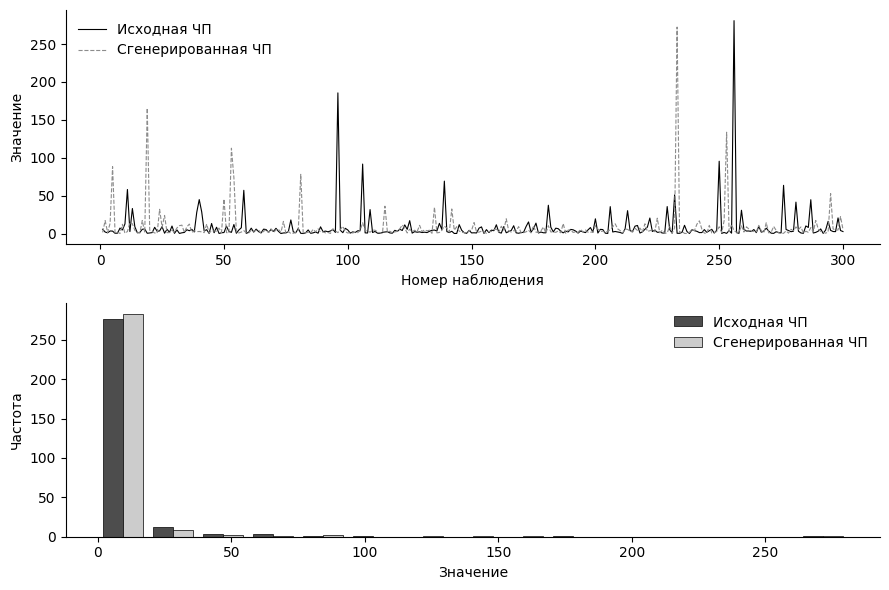

|   Левая граница |   Правая граница |   Частота X |   Частота Y |
|----------------:|-----------------:|------------:|------------:|
|        0.000000 |        18.729196 |  276.000000 |  283.000000 |
|       18.729196 |        37.458392 |   12.000000 |    8.000000 |
|       37.458392 |        56.187588 |    4.000000 |    2.000000 |
|       56.187588 |        74.916784 |    4.000000 |    1.000000 |
|       74.916784 |        93.645980 |    1.000000 |    2.000000 |
|       93.645980 |       112.375176 |    1.000000 |    0.000000 |
|      112.375176 |       131.104372 |    0.000000 |    1.000000 |
|      131.104372 |       149.833568 |    0.000000 |    1.000000 |
|      149.833568 |       168.562764 |    0.000000 |    1.000000 |
|      168.562764 |       187.291960 |    1.000000 |    0.000000 |
|      187.291960 |       206.021156 |    0.000000 |    0.000000 |
|      206.021156 |       224.750352 |    0.000000 |    0.000000 |
|      224.750352 |       243.479548 |    0.000000 |    0.000000 |
|      243.479548 |       262.208744 |    0.000000 |    0.000000 |
|      262.208744 |       280.937940 |    1.000000 |    1.000000 |

In [13]:
edges = np.linspace(0, max(x.max(), y.max()), 16)
counts_x, _ = np.histogram(x, bins=edges)
counts_y, _ = np.histogram(y, bins=edges)
assert counts_x.sum() == counts_y.sum() == N

fig, axes = plt.subplots(2, 1, figsize=(9, 6))
axes[0].plot(np.arange(1, N+1), x, color="black", linewidth=0.8, label="Исходная ЧП")
axes[0].plot(np.arange(1, N+1), y, color="0.55", linestyle="--", linewidth=0.8,
             label="Сгенерированная ЧП")
axes[0].set(xlabel="Номер наблюдения", ylabel="Значение")
axes[0].legend(frameon=False)
axes[1].hist([x, y], bins=edges, color=["0.3", "0.8"], edgecolor="black",
             linewidth=0.5, label=["Исходная ЧП", "Сгенерированная ЧП"])
axes[1].set(xlabel="Значение", ylabel="Частота")
axes[1].legend(frameon=False)
fig.tight_layout()
plt.show()

show_table(pd.DataFrame({"Левая граница": edges[:-1], "Правая граница": edges[1:],
                        "Частота X": counts_x, "Частота Y": counts_y}), index=False)

## 9. Автокорреляция нового ряда и взаимная корреляция

Снова вычисляем попарные коэффициенты Пирсона. В форме 3 проценты:

$$\delta_k(r)=\frac{|r_k^{(Y)}-r_k^{(X)}|}{|r_k^{(X)}|}\cdot100\%.$$

Когда исходный коэффициент близок к нулю, такие проценты могут быть большими,
даже если оба коэффициента малы. Для вывода проверяем сами коэффициенты и границы.

**Форма 3. Коэффициенты автокорреляции.**

|                    |          1 |         2 |          3 |         4 |         5 |          6 |          7 |          8 |         9 |         10 |
|:-------------------|-----------:|----------:|-----------:|----------:|----------:|-----------:|-----------:|-----------:|----------:|-----------:|
| Исходная ЧП        |  -0.041000 | -0.039000 |   0.034000 | -0.040000 | -0.045000 |   0.135000 |  -0.029000 |  -0.057000 | -0.027000 |   0.082000 |
| Сгенерированная ЧП |   0.019000 | -0.032000 |  -0.008000 | -0.035000 | -0.018000 |  -0.016000 |   0.026000 |   0.015000 | -0.016000 |  -0.010000 |
| Отклонение, %      | 147.345000 | 16.151000 | 124.677000 | 13.043000 | 60.381000 | 112.138000 | 189.949000 | 125.403000 | 39.053000 | 111.744000 |

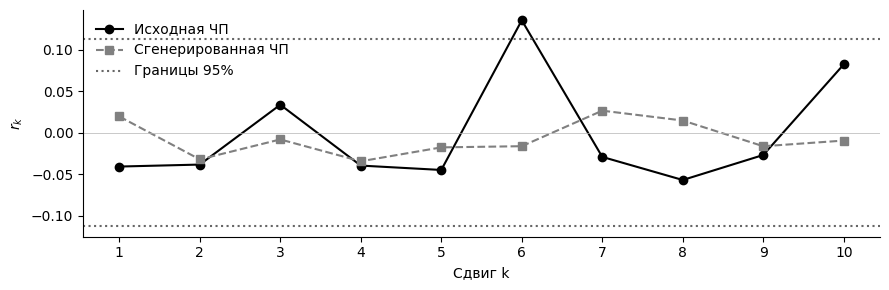

Максимум |r_k| нового ряда: 0.034615.
Поточечные границы 95%: ±0.113161.
Взаимная корреляция X и Y: -0.036116.
Льюнг–Бокс нового ряда (дополнительно): Q=1.361623; p-value=0.999306.


In [14]:
acf_y = pairwise_acf(y)
acf_errors = np.divide(np.abs(acf_y-acf_x), np.abs(acf_x),
                        out=np.full_like(acf_x, np.nan), where=np.abs(acf_x) > 0) * 100
form3 = pd.DataFrame([acf_x, acf_y, acf_errors], columns=LAGS,
                      index=["Исходная ЧП", "Сгенерированная ЧП", "Отклонение, %"])
form3.columns.name = "Лаг k"
display(Markdown("**Форма 3. Коэффициенты автокорреляции.**"))
show_table(form3.round(3))

fig, ax = plt.subplots()
ax.plot(LAGS, acf_x, "ko-", label="Исходная ЧП")
ax.plot(LAGS, acf_y, "s--", color="0.5", label="Сгенерированная ЧП")
ax.axhline(acf_limit, color="0.4", linestyle=":", label="Границы 95%")
ax.axhline(-acf_limit, color="0.4", linestyle=":")
ax.axhline(0, color="0.7", linewidth=0.5)
ax.set(xlabel="Сдвиг k", ylabel=r"$r_k$", xticks=LAGS)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

cross_correlation = pearson(x, y)
q_y, pvalue_y = ljung_box(y)
print(f"Максимум |r_k| нового ряда: {np.max(np.abs(acf_y)):.6f}.")
print(f"Поточечные границы 95%: ±{acf_limit:.6f}.")
print(f"Взаимная корреляция X и Y: {cross_correlation:.6f}.")
print(f"Льюнг–Бокс нового ряда (дополнительно): Q={q_y:.6f}; p-value={pvalue_y:.6f}.")

Взаимная корреляция относится к двум рядам без сдвига:

$$r_{XY}=\frac{\sum_{i=1}^N(X_i-\widetilde m_X)(Y_i-\widetilde m_Y)}
{\sqrt{\sum_{i=1}^N(X_i-\widetilde m_X)^2}\sqrt{\sum_{i=1}^N(Y_i-\widetilde m_Y)^2}}.$$

Малая линейная корреляция не доказывает независимость. При стандартном seed
все десять коэффициентов нового ряда находятся внутри указанных границ.

## 10. Все исходные и сгенерированные значения

В таблице доступны все 300 пар значений и равномерные числа генератора.
Раскрывающаяся таблица нужна для проверки конкретных наблюдений; графики и
сводные характеристики выше используют весь массив, а не только первые строки.

In [15]:
all_values = pd.DataFrame({"i": np.arange(1, N+1), "X_i": x,
                           "U₁": u1, "U₂": u2, "Y_i": y})
display(Markdown("<details><summary>Показать все 300 строк</summary>\n\n" +
                 all_values.to_markdown(index=False, floatfmt=".8f") + "\n\n</details>"))

<details><summary>Показать все 300 строк</summary>

|            i |          X_i |         U₁ |         U₂ |          Y_i |
|-------------:|-------------:|-----------:|-----------:|-------------:|
|   1.00000000 |   5.61817205 | 0.39113228 | 0.69791910 |   1.53360269 |
|   2.00000000 |   1.96132338 | 0.02957888 | 0.01810177 |  17.10659832 |
|   3.00000000 |   0.95896627 | 0.08588186 | 0.73597644 |   1.30719918 |
|   4.00000000 |   3.34226925 | 0.41620571 | 0.04129750 |  13.58957837 |
|   5.00000000 |   3.23854620 | 0.95767924 | 0.26998353 |  88.24692874 |
|   6.00000000 |   0.32995368 | 0.57722867 | 0.79343957 |   0.98662507 |
|   7.00000000 |   0.50593862 | 0.24116574 | 0.63238196 |   1.95408678 |
|   8.00000000 |   7.17405661 | 0.81424656 | 0.99597140 |   0.01721315 |
|   9.00000000 |   4.75881447 | 0.53617508 | 0.05741153 |  12.18479053 |
|  10.00000000 |  12.69518606 | 0.15809477 | 0.92658412 |   0.32514170 |
|  11.00000000 |  58.10667878 | 0.66399561 | 0.53126900 |   2.69700497 |
|  12.00000000 |   2.58778952 | 0.76465826 | 0.03353540 |  14.47737155 |
|  13.00000000 |  33.03094563 | 0.74726532 | 0.04949332 |  12.81761871 |
|  14.00000000 |   8.89468535 | 0.10462993 | 0.37125740 |   4.22515284 |
|  15.00000000 |   0.98670570 | 0.46662467 | 0.67220245 |   1.69369356 |
|  16.00000000 |   1.41822019 | 0.02533914 | 0.87287873 |   0.57974515 |
|  17.00000000 |   5.60874963 | 0.69725224 | 0.01780675 |  17.17666771 |
|  18.00000000 |   5.89967161 | 0.01277571 | 0.72528544 |   1.36959541 |
|  19.00000000 |   0.32563964 | 0.97840816 | 0.08582388 | 165.48615150 |
|  20.00000000 |   0.73708237 | 0.23193411 | 0.36234618 |   4.32875226 |
|  21.00000000 |   1.19277850 | 0.51911045 | 0.54942037 |   2.55375002 |
|  22.00000000 |   8.22489277 | 0.17360304 | 0.84192635 |   0.73369763 |
|  23.00000000 |   2.98079740 | 0.69306900 | 0.90830462 |   0.41010456 |
|  24.00000000 |   3.43565555 | 0.98572529 | 0.62231627 |  31.96601805 |
|  25.00000000 |   9.09352390 | 0.22600256 | 0.14259659 |   8.30539535 |
|  26.00000000 |   0.40281571 | 0.81745289 | 0.00369853 |  23.87835339 |
|  27.00000000 |   5.62372732 | 0.52846339 | 0.75829893 |   1.17978888 |
|  28.00000000 |   1.60824978 | 0.75402263 | 0.75027929 |   1.22512569 |
|  29.00000000 |   9.91962366 | 0.87729480 | 0.36499478 |   4.29769668 |
|  30.00000000 |   0.26659133 | 0.17057684 | 0.65870874 |   1.78016200 |
|  31.00000000 |   4.80700386 | 0.39884648 | 0.17639708 |   7.39833838 |
|  32.00000000 |   0.10920043 | 0.58305454 | 0.08841551 |  10.34353020 |
|  33.00000000 |   0.95280394 | 0.05707264 | 0.07437442 |  11.08094831 |
|  34.00000000 |   1.45576112 | 0.32427779 | 0.71948025 |   1.40386283 |
|  35.00000000 |   4.99567238 | 0.09963797 | 0.12707853 |   8.79668407 |
|  36.00000000 |   3.70770686 | 0.62335851 | 0.05367323 |  12.47189763 |
|  37.00000000 |   5.53866041 | 0.66515641 | 0.70179822 |   1.50996778 |
|  38.00000000 |   2.06825573 | 0.91655048 | 0.42428096 |   3.65589062 |
|  39.00000000 |  28.04754299 | 0.50468772 | 0.56316501 |   2.44838842 |
|  40.00000000 |  44.79204767 | 0.46767173 | 0.53034697 |   2.70441191 |
|  41.00000000 |  28.59260698 | 0.02061691 | 0.59733521 |   2.19720662 |
|  42.00000000 |   3.31218010 | 0.62622221 | 0.76095153 |   1.16489858 |
|  43.00000000 |   5.09352942 | 0.07604140 | 0.05277365 |  12.54397098 |
|  44.00000000 |   0.09855883 | 0.30132175 | 0.82515555 |   0.81949456 |
|  45.00000000 |  13.25402738 | 0.27779108 | 0.43826392 |   3.51762458 |
|  46.00000000 |   1.04454967 | 0.47959341 | 0.45323348 |   3.37440907 |
|  47.00000000 |   8.32090686 | 0.68620611 | 0.46877015 |   3.23068591 |
|  48.00000000 |   0.07655887 | 0.86511704 | 0.18482025 |   7.19943332 |
|  49.00000000 |   1.00827782 | 0.15479759 | 0.69977545 |   1.52227587 |
|  50.00000000 |   1.31976315 | 0.96957827 | 0.50959734 |  45.43344126 |
|  51.00000000 |   9.76667129 | 0.75291600 | 0.74072182 |   1.27979344 |
|  52.00000000 |   2.74576461 | 0.23073768 | 0.87614289 |   0.56382903 |
|  53.00000000 |   1.56828700 | 0.97455247 | 0.18817666 | 112.57524350 |
|  54.00000000 |  11.89018192 | 0.98734540 | 0.33457079 |  73.79149282 |
|  55.00000000 |   0.34504206 | 0.68639788 | 0.66935081 |   1.71182150 |
|  56.00000000 |   4.65001582 | 0.38862594 | 0.82858400 |   0.80181418 |
|  57.00000000 |   7.64724793 | 0.01828474 | 0.63659322 |   1.92578453 |
|  58.00000000 |  57.03848140 | 0.56645840 | 0.40256675 |   3.87990649 |
|  59.00000000 |   0.09392040 | 0.64913688 | 0.80348713 |   0.93296621 |
|  60.00000000 |   1.82704825 | 0.64837693 | 0.83934093 |   0.74681224 |
|  61.00000000 |   7.10520939 | 0.19155202 | 0.36317280 |   4.31903565 |
|  62.00000000 |   1.88326273 | 0.43951653 | 0.49421150 |   3.00532246 |
|  63.00000000 |   5.81843324 | 0.62814205 | 0.37952186 |   4.13127144 |
|  64.00000000 |   2.45078186 | 0.85162921 | 0.34092595 |   4.58858594 |
|  65.00000000 |   0.93811472 | 0.00275620 | 0.99178815 |   0.03516095 |
|  66.00000000 |   5.82197518 | 0.40729533 | 0.49517285 |   2.99703584 |
|  67.00000000 |   5.23958173 | 0.81971198 | 0.32336021 |   4.81415143 |
|  68.00000000 |   1.57232610 | 0.39745543 | 0.73124442 |   1.33470424 |
|  69.00000000 |   5.49667283 | 0.85415899 | 0.23524025 |   6.17082470 |
|  70.00000000 |   2.73606847 | 0.52038721 | 0.75748823 |   1.18435010 |
|  71.00000000 |   6.88317798 | 0.32670046 | 0.31487472 |   4.92754344 |
|  72.00000000 |   2.84266857 | 0.08025294 | 0.26617288 |   5.64403997 |
|  73.00000000 |   0.05714911 | 0.64539764 | 0.74096144 |   1.27841427 |
|  74.00000000 |   0.74938661 | 0.07334212 | 0.02339282 |  16.01319331 |
|  75.00000000 |   0.91633586 | 0.16828205 | 0.91485830 |   0.37944814 |
|  76.00000000 |   2.43392002 | 0.74013444 | 0.51463718 |   2.83263126 |
|  77.00000000 |  17.94931520 | 0.68950047 | 0.99921850 |   0.00333371 |
|  78.00000000 |   2.12172006 | 0.41130814 | 0.91164769 |   0.39443901 |
|  79.00000000 |   1.05626952 | 0.60221776 | 0.75447740 |   1.20133274 |
|  80.00000000 |   6.64472573 | 0.72581856 | 0.37619063 |   4.16886476 |
|  81.00000000 |   0.31471403 | 0.94140255 | 0.31381584 |  78.10762995 |
|  82.00000000 |   0.00882026 | 0.54917212 | 0.96636790 |   0.14587870 |
|  83.00000000 |   1.01304551 | 0.75962064 | 0.78722514 |   1.02015433 |
|  84.00000000 |   4.74177413 | 0.17002053 | 0.66109209 |   1.76476133 |
|  85.00000000 |   0.24387023 | 0.53896132 | 0.83529858 |   0.76739831 |
|  86.00000000 |   0.90299487 | 0.60320033 | 0.26835064 |   5.60929378 |
|  87.00000000 |   2.02046407 | 0.59222143 | 0.60337444 |   2.15431153 |
|  88.00000000 |   0.44828656 | 0.07734278 | 0.23288411 |   6.21374917 |
|  89.00000000 |   8.84209099 | 0.65647222 | 0.65665568 |   1.79347314 |
|  90.00000000 |   2.48690372 | 0.03517903 | 0.60890338 |   2.11541572 |
|  91.00000000 |   3.20380190 | 0.13213413 | 0.80693110 |   0.91472802 |
|  92.00000000 |   2.34372078 | 0.22466558 | 0.71347107 |   1.43962686 |
|  93.00000000 |   3.36788219 | 0.67068427 | 0.97152309 |   0.12319170 |
|  94.00000000 |   5.31664005 | 0.70905513 | 0.22617193 |   6.33845569 |
|  95.00000000 |   1.47453704 | 0.06412173 | 0.45508697 |   3.35700652 |
|  96.00000000 | 185.60540491 | 0.87403765 | 0.75069729 |   1.22275073 |
|  97.00000000 |   4.22074364 | 0.63931576 | 0.29488684 |   5.20719839 |
|  98.00000000 |   1.15199384 | 0.76007682 | 0.10396862 |   9.65256316 |
|  99.00000000 |   6.89053278 | 0.61036171 | 0.56017306 |   2.47110300 |
| 100.00000000 |   4.68115172 | 0.29806678 | 0.84842514 |   0.70090940 |
| 101.00000000 |   0.59820421 | 0.09206982 | 0.74628620 |   1.24788059 |
| 102.00000000 |   2.16152737 | 0.27643418 | 0.83310043 |   0.77863447 |
| 103.00000000 |   1.33055800 | 0.72771176 | 0.65411266 |   1.81001881 |
| 104.00000000 |   3.58838282 | 0.11781050 | 0.75911320 |   1.17521244 |
| 105.00000000 |   3.72013047 | 0.13415008 | 0.39551677 |   3.95524389 |
| 106.00000000 |  91.66518222 | 0.79339980 | 0.03519706 |  14.27115453 |
| 107.00000000 |   0.88184010 | 0.61747536 | 0.41537449 |   3.74635578 |
| 108.00000000 |   0.69908127 | 0.45316664 | 0.43889436 |   3.51149507 |
| 109.00000000 |  31.60759791 | 0.86227629 | 0.67083364 |   1.70238551 |
| 110.00000000 |   1.32365720 | 0.59996943 | 0.34903910 |   4.48829936 |
| 111.00000000 |   2.77502621 | 0.54766743 | 0.35842577 |   4.37513955 |
| 112.00000000 |   0.48904754 | 0.88576400 | 0.56515394 |   2.43335532 |
| 113.00000000 |   0.24516435 | 0.09319992 | 0.82965448 |   0.79630875 |
| 114.00000000 |   1.65433640 | 0.85800258 | 0.97938616 |   0.08881868 |
| 115.00000000 |   1.95550388 | 0.98777991 | 0.58568540 |  36.05459295 |
| 116.00000000 |   2.39089563 | 0.23435297 | 0.61660784 |   2.06180012 |
| 117.00000000 |   0.81545813 | 0.40471982 | 0.49176269 |   3.02650361 |
| 118.00000000 |   0.41063414 | 0.53386316 | 0.80830496 |   0.90747418 |
| 119.00000000 |   4.20266892 | 0.05604744 | 0.60197708 |   2.16419829 |
| 120.00000000 |   2.82509377 | 0.14269613 | 0.51588066 |   2.82234060 |
| 121.00000000 |   5.66400548 | 0.48919782 | 0.23501053 |   6.17499084 |
| 122.00000000 |   4.02993239 | 0.14256009 | 0.06899749 |  11.40093716 |
| 123.00000000 |  11.39265420 | 0.27921296 | 0.19148240 |   7.04843115 |
| 124.00000000 |   5.48812603 | 0.47995891 | 0.83458379 |   0.77104881 |
| 125.00000000 |  16.99687900 | 0.81957436 | 0.25352222 |   5.85167980 |
| 126.00000000 |   0.54884665 | 0.30438795 | 0.58212909 |   2.30716235 |
| 127.00000000 |   2.48242001 | 0.66479333 | 0.35719398 |   4.38981909 |
| 128.00000000 |   1.74935213 | 0.55360017 | 0.56089358 |   2.46562178 |
| 129.00000000 |   2.18054319 | 0.62788414 | 0.07839707 |  10.85633792 |
| 130.00000000 |   1.33626964 | 0.11406757 | 0.55465664 |   2.51330298 |
| 131.00000000 |   1.75755257 | 0.08584496 | 0.32286863 |   4.82063892 |
| 132.00000000 |   1.25749163 | 0.13476289 | 0.42962945 |   3.60247299 |
| 133.00000000 |   2.98278502 | 0.19627168 | 0.36091262 |   4.34565601 |
| 134.00000000 |   4.32778033 | 0.32238669 | 0.94115663 |   0.25860106 |
| 135.00000000 |   4.56558348 | 0.97822944 | 0.59748040 |  34.71082080 |
| 136.00000000 |   3.34643165 | 0.29616472 | 0.81483199 |   0.87317979 |
| 137.00000000 |  13.45963471 | 0.46050704 | 0.71822778 |   1.41129229 |
| 138.00000000 |   5.16042807 | 0.33034057 | 0.36765330 |   4.26675048 |
| 139.00000000 |  69.15622636 | 0.35037916 | 0.10217379 |   9.72681863 |
| 140.00000000 |   2.55294283 | 0.06248867 | 0.18484113 |   7.19895139 |
| 141.00000000 |   1.26837783 | 0.92600136 | 0.64158589 |   1.89247228 |
| 142.00000000 |   3.00998713 | 0.99577260 | 0.61794678 |  32.44089117 |
| 143.00000000 |   0.10661434 | 0.10556292 | 0.35971682 |   4.35980773 |
| 144.00000000 |   0.12226544 | 0.87327369 | 0.11987423 |   9.04554748 |
| 145.00000000 |  11.74398795 | 0.89632251 | 0.46701793 |   3.24665469 |
| 146.00000000 |   4.30891647 | 0.25251495 | 0.68244120 |   1.62923355 |
| 147.00000000 |   1.08861211 | 0.67665160 | 0.74645417 |   1.24692098 |
| 148.00000000 |   0.22838052 | 0.85830532 | 0.89210422 |   0.48684541 |
| 149.00000000 |   4.24293056 | 0.01421076 | 0.40854556 |   3.81704241 |
| 150.00000000 |   0.83967695 | 0.54202919 | 0.36947282 |   4.24569941 |
| 151.00000000 |   0.97172959 | 0.97338374 | 0.80676030 |  14.47168847 |
| 152.00000000 |   0.72857177 | 0.92550630 | 0.60823771 |   2.12007990 |
| 153.00000000 |   7.10171743 | 0.11509435 | 0.65388433 |   1.81150754 |
| 154.00000000 |   8.76755564 | 0.05754689 | 0.47913814 |   3.13740220 |
| 155.00000000 |   0.13799158 | 0.64213118 | 0.62999260 |   1.97022868 |
| 156.00000000 |   5.13494139 | 0.66132721 | 0.91459315 |   0.38068417 |
| 157.00000000 |   1.32066137 | 0.39310511 | 0.52264674 |   2.76677760 |
| 158.00000000 |   4.48641335 | 0.80071029 | 0.53962206 |   2.63048236 |
| 159.00000000 |   3.77757647 | 0.63816467 | 0.28994446 |   5.27927199 |
| 160.00000000 |  11.58202365 | 0.04363709 | 0.26467890 |   5.66804116 |
| 161.00000000 |   1.53407409 | 0.87959415 | 0.68704538 |   1.60056165 |
| 162.00000000 |   0.58250576 | 0.45071289 | 0.10602597 |   9.56900807 |
| 163.00000000 |   9.18445574 | 0.11041956 | 0.34679847 |   4.51576081 |
| 164.00000000 |   1.01659172 | 0.96711405 | 0.74927141 |  19.45390193 |
| 165.00000000 |   2.61322584 | 0.23414741 | 0.45509608 |   3.35692111 |
| 166.00000000 |   3.97835525 | 0.04594006 | 0.62169590 |   2.02675825 |
| 167.00000000 |  10.30182863 | 0.59876131 | 0.41157949 |   3.78549334 |
| 168.00000000 |   0.88498496 | 0.58113591 | 0.48899332 |   3.05058499 |
| 169.00000000 |   0.38734717 | 0.84810134 | 0.11632102 |   9.17385248 |
| 170.00000000 |   1.28477517 | 0.47810973 | 0.84205062 |   0.73306828 |
| 171.00000000 |   1.61561302 | 0.54375124 | 0.77310777 |   1.09731730 |
| 172.00000000 |   9.20096223 | 0.44017083 | 0.58939158 |   2.25429331 |
| 173.00000000 |  15.33933078 | 0.26055849 | 0.34995183 |   4.47716338 |
| 174.00000000 |   1.75789470 | 0.79891295 | 0.82090979 |   0.84149186 |
| 175.00000000 |   6.24033442 | 0.10891206 | 0.08745211 |  10.39024794 |
| 176.00000000 |  13.74135199 | 0.46666792 | 0.65851558 |   1.78141256 |
| 177.00000000 |   0.73169810 | 0.88690315 | 0.69563275 |   1.54759472 |
| 178.00000000 |   1.96879473 | 0.33915455 | 0.45932208 |   3.31750741 |
| 179.00000000 |   0.99862745 | 0.31549355 | 0.12988299 |   8.70360339 |
| 180.00000000 |   0.95548179 | 0.72644788 | 0.88699528 |   0.51133559 |
| 181.00000000 |  37.32623879 | 0.05981698 | 0.08662375 |  10.43083095 |
| 182.00000000 |   8.34631235 | 0.64039373 | 0.61689326 |   2.05982679 |
| 183.00000000 |   2.15495572 | 0.48973814 | 0.60932565 |   2.11245958 |
| 184.00000000 |   7.07564549 | 0.01659360 | 0.69061933 |   1.57843751 |
| 185.00000000 |   6.37945604 | 0.38279462 | 0.44550365 |   3.44776040 |
| 186.00000000 |   3.05312186 | 0.19908475 | 0.78561439 |   1.02888819 |
| 187.00000000 |   0.86095104 | 0.02264659 | 0.04531325 |  13.19387829 |
| 188.00000000 |   3.22969157 | 0.26584081 | 0.91541320 |   0.37686252 |
| 189.00000000 |   2.09127881 | 0.39615933 | 0.34237322 |   4.57052251 |
| 190.00000000 |   5.42629542 | 0.02321749 | 0.32618988 |   4.77699918 |
| 191.00000000 |   4.93382126 | 0.44224357 | 0.70743997 |   1.47582555 |
| 192.00000000 |   3.28917902 | 0.74746872 | 0.60521730 |   2.14130767 |
| 193.00000000 |   0.58370147 | 0.55557861 | 0.71555835 |   1.42717024 |
| 194.00000000 |   3.31410416 | 0.00145809 | 0.26686566 |   5.63295592 |
| 195.00000000 |   2.14069807 | 0.79834330 | 0.61731417 |   2.05691834 |
| 196.00000000 |   1.23436836 | 0.10469058 | 0.33176509 |   4.70473286 |
| 197.00000000 |   4.74219906 | 0.52307981 | 0.65481314 |   1.80545486 |
| 198.00000000 |   7.86229118 | 0.08478961 | 0.66475729 |   1.74118560 |
| 199.00000000 |   1.73454090 | 0.35981519 | 0.61301149 |   2.08674337 |
| 200.00000000 |  19.40781994 | 0.18854439 | 0.08726125 |  10.39956451 |
| 201.00000000 |   0.66004619 | 0.77056578 | 0.24702305 |   5.96241838 |
| 202.00000000 |   5.51490906 | 0.28065261 | 0.52967807 |   2.70979341 |
| 203.00000000 |   5.22871972 | 0.62434943 | 0.47602798 |   3.16517152 |
| 204.00000000 |   0.45966709 | 0.70828345 | 0.73945976 |   1.28706497 |
| 205.00000000 |   0.10258411 | 0.49583049 | 0.48440800 |   3.09075868 |
| 206.00000000 |  35.51361945 | 0.45958581 | 0.31046719 |   4.98765319 |
| 207.00000000 |   2.05680451 | 0.64072266 | 0.12073322 |   9.01510098 |
| 208.00000000 |   2.69939119 | 0.69426702 | 0.04924205 |  12.83932261 |
| 209.00000000 |   2.01398383 | 0.85107463 | 0.23522551 |   6.17109202 |
| 210.00000000 |   1.39884287 | 0.97436669 | 0.94381785 |   3.89693273 |
| 211.00000000 |   0.13872244 | 0.64356355 | 0.84632345 |   0.71148547 |
| 212.00000000 |   6.11036141 | 0.77335096 | 0.25069509 |   5.89949788 |
| 213.00000000 |  30.18302734 | 0.48392126 | 0.27697382 |   5.47442576 |
| 214.00000000 |   3.76840565 | 0.09165211 | 0.46560536 |   3.25957174 |
| 215.00000000 |   2.59551015 | 0.00061844 | 0.65127470 |   1.82855961 |
| 216.00000000 |   9.71787789 | 0.25677833 | 0.19368958 |   6.99956044 |
| 217.00000000 |  10.65561991 | 0.39093144 | 0.39209504 |   3.99229462 |
| 218.00000000 |   0.66176037 | 0.23611898 | 0.18471530 |   7.20185525 |
| 219.00000000 |   2.27270540 | 0.47251701 | 0.61029591 |   2.10567498 |
| 220.00000000 |   5.55332072 | 0.04057002 | 0.04895802 |  12.86398908 |
| 221.00000000 |   8.46842711 | 0.08361983 | 0.52617823 |   2.73806211 |
| 222.00000000 |  20.45707395 | 0.04710484 | 0.41937162 |   3.70551838 |
| 223.00000000 |   2.70737937 | 0.78503782 | 0.31378206 |   4.94236632 |
| 224.00000000 |   4.47072785 | 0.31841537 | 0.57567284 |   2.35471899 |
| 225.00000000 |   1.61692378 | 0.06697032 | 0.00866254 |  20.24926936 |
| 226.00000000 |   1.85864949 | 0.24774849 | 0.79596478 |   0.97307556 |
| 227.00000000 |   0.75946523 | 0.51387401 | 0.36976727 |   4.24230238 |
| 228.00000000 |   0.53514918 | 0.10706281 | 0.95152455 |   0.21188367 |
| 229.00000000 |  35.59966136 | 0.63045169 | 0.83604037 |   0.76361323 |
| 230.00000000 |   5.32373597 | 0.32663065 | 0.11037987 |   9.39740378 |
| 231.00000000 |   0.56462223 | 0.28189888 | 0.96837797 |   0.13701838 |
| 232.00000000 |  51.00832745 | 0.58421047 | 0.16529984 |   7.67540673 |
| 233.00000000 |   0.33250052 | 0.95153319 | 0.01756044 | 272.41868994 |
| 234.00000000 |   0.27953683 | 0.03191452 | 0.75182471 |   1.21635150 |
| 235.00000000 |   1.57151788 | 0.26893154 | 0.50878599 |   2.88139016 |
| 236.00000000 |  10.88798840 | 0.23889682 | 0.97195973 |   0.12127566 |
| 237.00000000 |   2.55054569 | 0.51170018 | 0.98343097 |   0.07124432 |
| 238.00000000 |   0.11313519 | 0.67798648 | 0.68915805 |   1.58746957 |
| 239.00000000 |   4.93968333 | 0.03400252 | 0.28866169 |   5.29817922 |
| 240.00000000 |   3.80620203 | 0.83439130 | 0.41021768 |   3.79962557 |
| 241.00000000 |   2.94497888 | 0.82496978 | 0.05552276 |  12.32743418 |
| 242.00000000 |   1.24356887 | 0.26459668 | 0.01971759 |  16.74201046 |
| 243.00000000 |   1.26926208 | 0.65011942 | 0.25612709 |   5.80809054 |
| 244.00000000 |   5.15319474 | 0.18358489 | 0.88261771 |   0.53243237 |
| 245.00000000 |   1.59796894 | 0.47890644 | 0.98057234 |   0.08365733 |
| 246.00000000 |   3.69070086 | 0.40849963 | 0.08064818 |  10.73562151 |
| 247.00000000 |   5.59825062 | 0.15153247 | 0.82420901 |   0.82438878 |
| 248.00000000 |   0.66090317 | 0.73688083 | 0.79811253 |   0.96158520 |
| 249.00000000 |   4.16182723 | 0.48813763 | 0.52588507 |   2.74043846 |
| 250.00000000 |  95.41370538 | 0.08759489 | 0.12272994 |   8.94515624 |
| 251.00000000 |   0.20017134 | 0.29350025 | 0.74779216 |   1.23928451 |
| 252.00000000 |   1.40636490 | 0.98258515 | 0.77714166 |  16.99253600 |
| 253.00000000 |   0.18234555 | 0.96036942 | 0.13753831 | 133.70220996 |
| 254.00000000 |   3.93986502 | 0.19756766 | 0.54670635 |   2.57486608 |
| 255.00000000 |   0.47409309 | 0.62455525 | 0.06307230 |  11.78380631 |
| 256.00000000 | 280.93793988 | 0.65979735 | 0.41920959 |   3.70716625 |
| 257.00000000 |   1.18113539 | 0.07490210 | 0.66108450 |   1.76481022 |
| 258.00000000 |   0.30250723 | 0.92102940 | 0.70211240 |   1.50805927 |
| 259.00000000 |  30.72642562 | 0.87126949 | 0.08950935 |  10.29109975 |
| 260.00000000 |   5.06339582 | 0.78380102 | 0.63296384 |   1.95016497 |
| 261.00000000 |   3.31053181 | 0.37364587 | 0.12475431 |   8.87539528 |
| 262.00000000 |   3.34448854 | 0.90915848 | 0.24860269 |   5.93523729 |
| 263.00000000 |   2.64289163 | 0.63552020 | 0.49428050 |   3.00472714 |
| 264.00000000 |   5.27638387 | 0.48395446 | 0.52877315 |   2.71708462 |
| 265.00000000 |   1.18041803 | 0.36463637 | 0.58515975 |   2.28502017 |
| 266.00000000 |   9.56459568 | 0.27584076 | 0.07977962 |  10.78179439 |
| 267.00000000 |   1.84439124 | 0.40425538 | 0.41923337 |   3.70692439 |
| 268.00000000 |   3.25497704 | 0.65408128 | 0.87380556 |   0.57521984 |
| 269.00000000 |   7.08865555 | 0.43805037 | 0.03549732 |  14.23493252 |
| 270.00000000 |   3.27719490 | 0.40431028 | 0.80952142 |   0.90106173 |
| 271.00000000 |   0.46462248 | 0.87175947 | 0.67033909 |   1.70553023 |
| 272.00000000 |   0.21040118 | 0.41536106 | 0.10960656 |   9.42738281 |
| 273.00000000 |   2.37268695 | 0.09472140 | 0.37625108 |   4.16817958 |
| 274.00000000 |   1.26926208 | 0.56628983 | 0.82081034 |   0.84200846 |
| 275.00000000 |   0.86095104 | 0.57441897 | 0.96964549 |   0.13144070 |
| 276.00000000 |  63.60824841 | 0.39171998 | 0.93217720 |   0.29947979 |
| 277.00000000 |   5.43573229 | 0.48715532 | 0.44839586 |   3.42016715 |
| 278.00000000 |   4.00743735 | 0.35363160 | 0.87706078 |   0.55936402 |
| 279.00000000 |   2.42489248 | 0.83798803 | 0.26973014 |   5.58742955 |
| 280.00000000 |   3.01274487 | 0.79772139 | 0.43455222 |   3.55389163 |
| 281.00000000 |  41.46000027 | 0.27304600 | 0.12910031 |   8.72937720 |
| 282.00000000 |   3.10791501 | 0.92245779 | 0.29594737 |   5.19189041 |
| 283.00000000 |   0.74184792 | 0.03735414 | 0.13065355 |   8.67838032 |
| 284.00000000 |   0.28499140 | 0.33895650 | 0.81187819 |   0.88866553 |
| 285.00000000 |  10.00308444 | 0.78129091 | 0.48993005 |   3.04242436 |
| 286.00000000 |   8.00968622 | 0.04980126 | 0.68573313 |   1.60871392 |
| 287.00000000 |  44.64600179 | 0.16880367 | 0.15941226 |   7.83005545 |
| 288.00000000 |   0.73132278 | 0.92493498 | 0.62899161 |   1.97700930 |
| 289.00000000 |   1.50068887 | 0.49050677 | 0.01755081 |  17.23840039 |
| 290.00000000 |   3.14243577 | 0.00274613 | 0.24409756 |   6.01321974 |
| 291.00000000 |   6.06272053 | 0.73478757 | 0.51189196 |   2.85543824 |
| 292.00000000 |   0.20869399 | 0.19447555 | 0.65049704 |   1.83365427 |
| 293.00000000 |   4.61263022 | 0.82004515 | 0.89693155 |   0.46383370 |
| 294.00000000 |  16.11177980 | 0.22006842 | 0.61946484 |   2.04208833 |
| 295.00000000 |   4.15293831 | 0.94118696 | 0.45732063 |  52.72804152 |
| 296.00000000 |   2.64020398 | 0.85359667 | 0.23334525 |   6.20531402 |
| 297.00000000 |   2.51049048 | 0.23350813 | 0.35704755 |   4.39156758 |
| 298.00000000 |  20.61052763 | 0.80637665 | 0.33483184 |   4.66549742 |
| 299.00000000 |   3.98104971 | 0.20707876 | 0.00522166 |  22.40773585 |
| 300.00000000 |   2.61478053 | 0.82590712 | 0.28191131 |   5.39908074 |

</details>

## 11. Сверка с готовым Excel

Этот раздел **не участвует** в получении результатов. Сравниваются исходный ряд,
сохранённые $U_1/U_2$, генерация, характеристики и коэффициенты автокорреляции.
Допускается небольшая погрешность представления чисел с плавающей точкой.

При изменении seed или варианта сверка со старой книгой пропускается: она содержит
конкретную реализацию варианта 16 с seed 8141.

In [16]:
book_path = LAB_DIR / "УИР_1_вариант_16_расчеты.xlsx"
if VARIANT == 16 and SEED == 8141 and book_path.exists():
    book = openpyxl.load_workbook(book_path, read_only=True, data_only=True)
    def column_values(sheet_name, column, start, end):
        return np.array([row[0] for row in book[sheet_name].iter_rows(
            min_row=start, max_row=end, min_col=column, max_col=column, values_only=True)], dtype=float)

    checks = [
        ("Исходные 300 чисел", x, column_values("Исходные данные", 2, 5, 304)),
        ("Равномерные U₁", u1, column_values("Генератор", 2, 12, 311)),
        ("Равномерные U₂", u2, column_values("Генератор", 3, 12, 311)),
        ("Сгенерированные 300 чисел", y, column_values("Генератор", 5, 12, 311)),
        ("АКФ исходного ряда", acf_x, column_values("Автокорреляция", 2, 5, 14)),
        ("АКФ нового ряда", acf_y, column_values("Автокорреляция", 3, 5, 14)),
        ("Параметры Hν", np.array([p, mu1, mu2]), column_values("Распределение", 2, 23, 25)),
    ]
    # Порядок столбцов Excel приводим к порядку строк нашей таблицы.
    excel_cols = [2, 10, 12, 14, 4, 6, 8]
    for name, calculated, start in [("Характеристики X", stats_x, 5), ("Характеристики Y", stats_y, 21)]:
        reference = np.array([[book["Статистика"].cell(r, c).value
                               for r in range(start, start+len(SIZES))] for c in excel_cols], dtype=float)
        checks.append((name, calculated.to_numpy(), reference))
    for name, calculated, start in [("Проценты формы 1", errors_x, 5), ("Проценты формы 2", errors_y, 21)]:
        # В Excel доли хранятся без умножения на 100 и показываются процентным форматом.
        reference = np.array([[book["Статистика"].cell(r, c+1).value * 100
                               for r in range(start, start+len(SIZES))] for c in excel_cols], dtype=float)
        checks.append((name, calculated.to_numpy(), reference))
    book.close()

    audit = []
    for name, calculated, reference in checks:
        np.testing.assert_allclose(calculated, reference, rtol=1e-10, atol=1e-10, err_msg=name)
        audit.append({"Проверка": name, "Максимальная разница": np.max(np.abs(calculated-reference)),
                      "Совпадает": True})
    show_table(pd.DataFrame(audit).set_index("Проверка"))
    print("Расчёт Python согласуется с сохранённой книгой Excel.")
else:
    print("Сверка пропущена: другая конфигурация или расчётная книга отсутствует.")

| Проверка                  |   Максимальная разница | Совпадает   |
|:--------------------------|-----------------------:|:------------|
| Исходные 300 чисел        |               0.000000 | True        |
| Равномерные U₁            |               0.000000 | True        |
| Равномерные U₂            |               0.000000 | True        |
| Сгенерированные 300 чисел |               0.000000 | True        |
| АКФ исходного ряда        |               0.000000 | True        |
| АКФ нового ряда           |               0.000000 | True        |
| Параметры Hν              |               0.000000 | True        |
| Характеристики X          |               0.000000 | True        |
| Характеристики Y          |               0.000000 | True        |
| Проценты формы 1          |               0.000000 | True        |
| Проценты формы 2          |               0.000000 | True        |

Расчёт Python согласуется с сохранённой книгой Excel.


## 12. Вывод

Проверяются свойства заданной и сформированной последовательностей. Теоретические
моменты модели согласованы с оценками по исходным данным; выборочные моменты
нового ряда в общем случае не обязаны совпадать с ними точно.

In [17]:
inside = np.max(np.abs(acf_y)) < acf_limit
display(Markdown(
    f"Для **варианта {VARIANT}** получены $\\widetilde m={mean_x:.4f}$, "
    f"$\\widetilde D={var_x:.4f}$ и $\\nu={cv_x:.4f}$. "
    "Выбрана двухфазная гиперэкспоненциальная модель со сбалансированными параметрами. "
    f"При seed **{SEED}** отклонения среднего и дисперсии нового ряда составляют "
    f"**{mean_error:.4f}%** и **{variance_error:.4f}%**. "
    f"Максимум $|r_k|$ нового ряда: **{np.max(np.abs(acf_y)):.4f}**, "
    f"граница: **{acf_limit:.4f}**; все проверенные коэффициенты "
    f"{'внутри' if inside else 'не находятся внутри'} поточечных границ. "
    f"Взаимная корреляция: **{cross_correlation:.4f}**. "
    "Эти проверки относятся к данной реализации и не доказывают независимость."))

Для **варианта 16** получены $\widetilde m=8.0208$, $\widetilde D=510.4309$ и $\nu=2.8168$. Выбрана двухфазная гиперэкспоненциальная модель со сбалансированными параметрами. При seed **8141** отклонения среднего и дисперсии нового ряда составляют **0.1010%** и **0.0867%**. Максимум $|r_k|$ нового ряда: **0.0346**, граница: **0.1132**; все проверенные коэффициенты внутри поточечных границ. Взаимная корреляция: **-0.0361**. Эти проверки относятся к данной реализации и не доказывают независимость.

### Где посмотреть в отчёте

| Результат | Страница PDF |
|---|---|
| Оценки и доверительные полуинтервалы | 2–3, форма 1 |
| Автокорреляция и Льюнг–Бокс | 4 |
| Гистограмма и распределение | 5–6 |
| Метод моментов и параметры | 6 |
| Генератор | 7 |
| Новые характеристики | 8, форма 2 |
| Сравнение графиков | 9 |
| Автокорреляция и взаимная корреляция | 10, форма 3 |

Источники: методичка УИР 1, «УИР1_Обработка рез-в ИМ.pdf» и исходная таблица
вариантов в `materials/`. Сдаваемый PDF: `3313_Якименко_Владислав_ЛР1.pdf`.